# GH-I model

After trying `test-0-x`, now, we proceed to propose canonical toy models for the paper and test basic properties, preparing for scanning.

`test-1-x` are for the main text gate-head (GH) model, which is more like `MoE`. We need to balance the simplicty of the model and the generalizability (can connect to different architectures).

In this model, the input $x\in \mathbb{R}^m$ is like query. We have a key matrix $K \in \mathbb{R}^{d\times m}$, and a value tensor $V \in \mathbb{R}^{d\times m \times m}$. The output of the gate is computed as:
$$
h =  (Vx)^T \mathrm{Softmax}(Kx) \in \mathbb{R}^m.
$$
We call this part G-I, gate model type I.
After the gate, we project the hidden state out with a head $W \in \mathbb{R}^{n\times m}$, and the final logits is:
$$
y = Wh \in \mathbb{R}^n.
$$

Visually, one can see
<img src="GHmodels.jpeg" alt="GHmodels" width="600">

We want the toy model to have the following properties:
- 1/3 scaling for gate part
- 3/4 situations of GH can show the 1/3 scaling, 1/4 situation means both high temperature.
- Maybe increasing Hessian, not necessary.

## GH-I model

`test-1-4` is for testing GH-I. The goals reached, except the Hessian part.

In [1]:
import torch
import torch.nn.functional as F
import torch.nn as nn
from dataclasses import dataclass
import matplotlib.pyplot as plt

In [2]:
# ---- Config ----
@dataclass
class Config:
    vocab_size: int = 128     # vocab size (n)
    n_embd: int = 32         # model width (m)
    beta: float = 1.0              # scaling factor for the logits
    beta_g: float = 1.0            # scaling factor for the gating
    teacher: bool = False             # whether to use teacher model
    d_gate: int = 8             # number of classes in gate

# ---- Utils ----
def rmsnorm(x: torch.Tensor):
    return F.rms_norm(x, (x.size(-1),))

# ---- Model ----
class GATE_I(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        if cfg.teacher:
            self.K = torch.nn.Parameter(torch.randn(cfg.d_gate, cfg.n_embd) * cfg.beta_g / (cfg.n_embd ** 0.5))
            self.V = torch.nn.Parameter(torch.randn(cfg.d_gate, cfg.n_embd, cfg.n_embd) / (cfg.n_embd ** 0.5))
        else:
            self.K = torch.nn.Parameter(torch.zeros(cfg.d_gate, cfg.n_embd))
            self.V = torch.nn.Parameter(torch.randn(cfg.d_gate, cfg.n_embd, cfg.n_embd) / (cfg.n_embd ** 0.5) / 4)
            #self.V = torch.nn.Parameter(torch.zeros(cfg.d_gate, cfg.n_embd, cfg.n_embd))

    def forward(self, x: torch.Tensor):
        # x: (batch_size, n_embd)
        # Compute gate logits
        gate_logits = F.linear(x, self.K)  # (batch_size, d_gate)
        gate_probs = F.softmax(gate_logits, dim=-1)  # (batch_size, d_gate)
        # Compute value
        Values = torch.einsum('bm,dam->bda', x, self.V)  # (batch_size, d_gate, n_embd)
        # Compute output as weighted sum of values
        output = torch.einsum('bd,bdm->bm', gate_probs, Values)
        return output
    
class GH_I(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.gate = GATE_I(cfg)
        self.head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        if cfg.teacher:
            self.head.weight.data.copy_(torch.randn(cfg.vocab_size, cfg.n_embd) / (cfg.n_embd ** 0.5))
        else:
            self.head.weight.data.zero_()
            
    def forward(self, x: torch.Tensor):
        # x: (batch_size, n_embd)
        x = rmsnorm(x)
        x = self.gate(x) + x  # residual connection
        x = rmsnorm(x)
        logits = self.head(x) * self.cfg.beta  # scale logits
        return logits

In [43]:
t_cfg = Config(beta = 1.0, beta_g = 500.0, teacher = True)
teacher = GH_I(t_cfg)
s_cfg = Config()
student = GH_I(s_cfg)
#with torch.no_grad():
    #new_V = teacher.V.detach().clone()
    #new_V[0] = 0 # no-op for the first path
    #teacher.K[0].mul_(10)
    #teacher.V.copy_(new_V)
    #student.V.copy_(teacher.V + torch.randn_like(teacher.V) * 0.2)
    #student.V.mul_(0.001)
init_V = student.gate.V.detach().clone()
batch_size = 2048
base_lr = 1e-1

optimizer = torch.optim.Adam(student.parameters(), lr=base_lr)

losses = []
s_logits_stds = []
#t_logits_stds = []
#entropies = []
#t_entropies = []
s_beta_G = []
V_diff = []

num_steps = 2000 # 18s
for step in range(num_steps):
    x = torch.randn(batch_size, s_cfg.n_embd)
    with torch.no_grad():
        teacher_logits = teacher(x)
        teacher_log_probs = F.log_softmax(teacher_logits, dim=-1)
    student_logits = student(x)
    student_log_probs = F.log_softmax(student_logits, dim=-1)
    loss = F.kl_div(student_log_probs, teacher_log_probs, reduction='batchmean', log_target=True)
    #loss = F.mse_loss(student_logits, teacher_logits)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    #s_logits_stds.append(student_logits.std(dim = -1).mean().item())
    s_logits_stds.append(student.head.weight.norm().item() / (s_cfg.vocab_size ** 0.5))
    #t_logits
    s_beta_G.append(student.gate.K.norm().item() / (s_cfg.d_gate ** 0.5))
    V_diff.append((student.gate.V - init_V).norm().item())
    #print(f"Step {step+1}/{num_steps}, Loss: {loss.item():.4f}, Student Beta_G: {s_beta_G[-1]:.4f}")

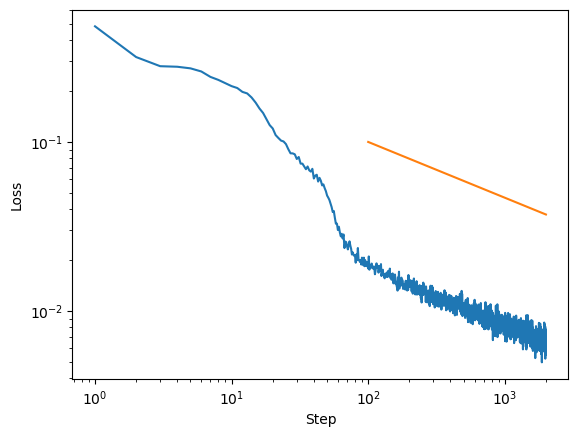

In [44]:
plt.plot(range(1, len(losses) + 1), losses)
plt.plot([100, 2000], [.1, .1/20**0.33])
plt.xlabel('Step')
plt.ylabel('Loss')
plt.xscale('log')
plt.yscale('log')

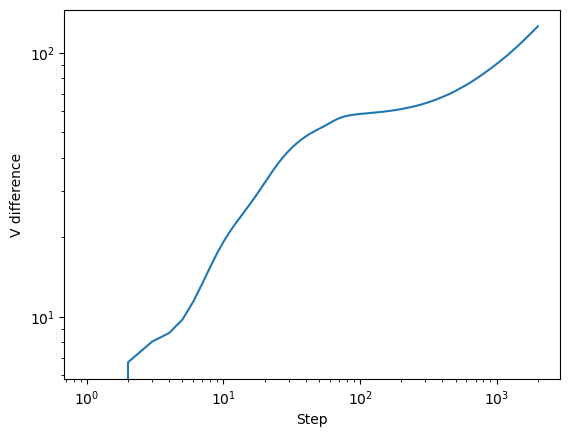

In [45]:
plt.plot(range(1, len(losses) + 1), V_diff)
plt.xlabel('Step')
plt.ylabel('V difference')
plt.xscale('log')
plt.yscale('log')

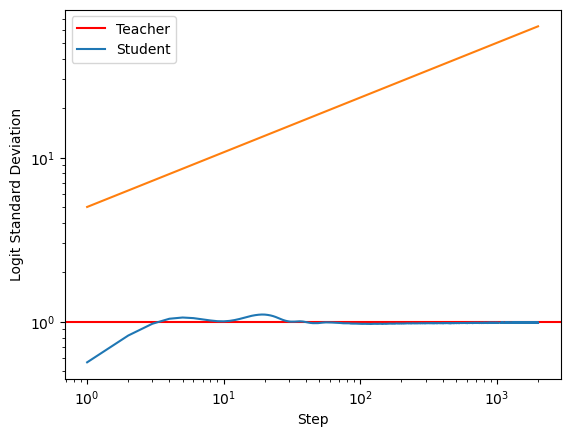

In [46]:
#plt.plot(range(1, len(losses) + 1), t_logits_stds, label='Teacher')
plt.axhline(t_cfg.beta, label='Teacher', color='red')
plt.plot(range(1, len(losses) + 1), s_logits_stds, label='Student')
plt.plot([1,2000], [5, 5 * 2000 ** (1/3)])
#plt.ylim(0,None)
plt.xlabel('Step')
plt.ylabel('Logit Standard Deviation')
plt.xscale('log')
plt.yscale('log')
plt.legend()

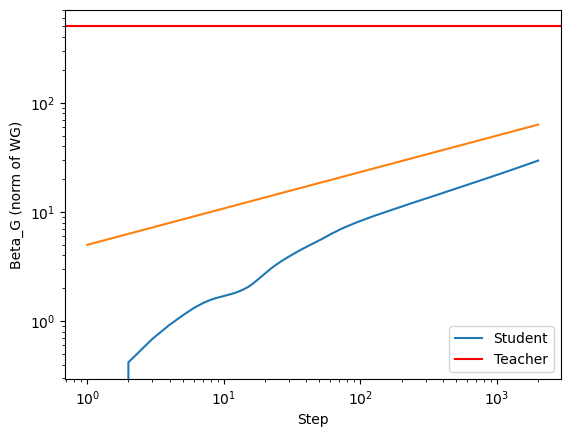

In [47]:
plt.plot(range(1, len(losses) + 1), s_beta_G, label='Student')
plt.axhline(t_cfg.beta_g, label='Teacher', color='red')
plt.plot([1,2000], [5, 5 * 2000 ** (1/3)])
plt.xlabel('Step')
plt.ylabel('Beta_G (norm of WG)')
plt.xscale('log')
plt.yscale('log')
plt.legend()

Initialization is a good engineering knob for tunning the first training regime.

Hessian trace almost not changing, top eigenvalues are decreasing.
- Hypothesis 1, we need qkv or qk to have increasing Hessian. [No seems]
- Hypothesis 2, we need no-op to have increasing Hessian, sparse V. [No]
- Hypthesis 3, initialization [No]
- Hypothesis 4, teacher and student should be different?
- Hypothesis 5, a lot of zero logits? or low rank!